# Notebook 02: Regression Trees (Variance Reduction) & Cost-Complexity Pruning ($R_\alpha(T)$)

In this notebook we explore:
1. **Piecewise-Constant Step Function Fitting:** How `DecisionTreeRegressorScratch` splits 1D feature space to minimize within-node target variance $\mathrm{Var}(S) = \frac{1}{|S|}\sum_{i \in S} (y^{(i)} - \bar{y}_S)^2$.
2. **Overfitting in Deep Regression Trees:** Watching a Depth-10 tree memorize every individual noisy point with $1$-sample leaves.
3. **Minimal Cost-Complexity Pruning ($R_\alpha(T) = R(T) + \alpha |T|$):** Sweeping $\alpha$ (`ccp_alpha`) to collapse weak subtrees and locate the validation MSE sweet spot.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

repo_root = Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.plot_theme import (
    AMBER,
    CORAL,
    CYAN,
    EMERALD,
    PURPLE,
    SLATE_BLUE,
    apply_github_dark_style,
    save_fig,
)
from src.trees_engine import DecisionTreeRegressorScratch

apply_github_dark_style()

## 1. Fitting Piecewise-Constant Step Curves Across Depths $D \in \{1, 3, 9\}$

In [2]:
rng = np.random.default_rng(2026)
m_tr = 75
X_tr = np.sort(rng.uniform(0.0, 6.0, size=(m_tr, 1)), axis=0)


def f_signal(x: np.ndarray) -> np.ndarray:
    return np.sin(x) + 0.35 * np.cos(2.5 * x)


y_tr = f_signal(X_tr).ravel() + rng.normal(0.0, 0.28, size=m_tr)

# Validation set for pruning selection
m_val = 60
X_val = np.sort(rng.uniform(0.0, 6.0, size=(m_val, 1)), axis=0)
y_val = f_signal(X_val).ravel() + rng.normal(0.0, 0.28, size=m_val)

X_dense = np.linspace(0.0, 6.0, 600).reshape(-1, 1)

tree_d1 = DecisionTreeRegressorScratch(max_depth=1).fit(X_tr, y_tr)
tree_d3 = DecisionTreeRegressorScratch(max_depth=3).fit(X_tr, y_tr)
tree_d9 = DecisionTreeRegressorScratch(max_depth=9, min_samples_split=2).fit(X_tr, y_tr)

print(f"Depth 1 MSE: {np.mean((tree_d1.predict(X_val) - y_val)**2):.4f} | Leaves: {tree_d1.count_leaves()}")
print(f"Depth 3 MSE: {np.mean((tree_d3.predict(X_val) - y_val)**2):.4f} | Leaves: {tree_d3.count_leaves()}")
print(f"Depth 9 MSE: {np.mean((tree_d9.predict(X_val) - y_val)**2):.4f} | Leaves: {tree_d9.count_leaves()}")

Depth 1 MSE: 0.1013 | Leaves: 2
Depth 3 MSE: 0.0844 | Leaves: 8
Depth 9 MSE: 0.1512 | Leaves: 59


## 2. Minimal Cost-Complexity Pruning Sweep ($R_\alpha(T) = R(T) + \alpha |T|$)


Optimal Cost-Complexity Alpha: alpha* = 0.01425 | Pruned Leaves = 2 | Min Val MSE = 0.1013


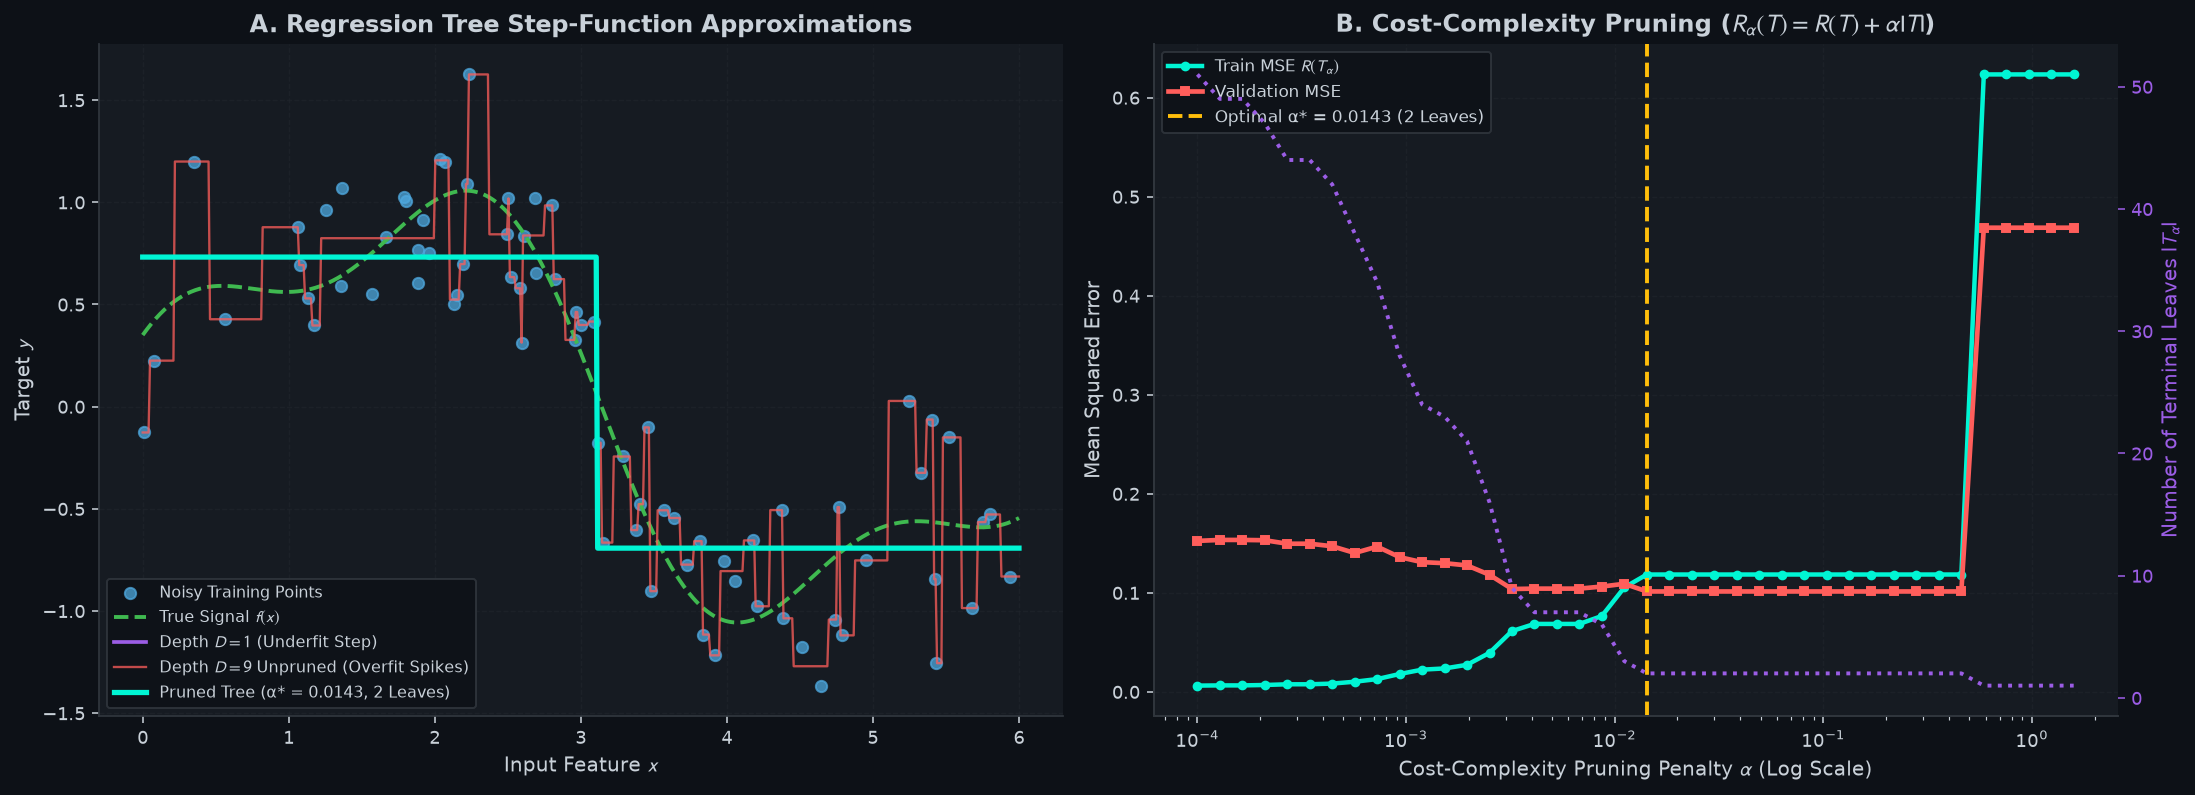

In [3]:
alphas = np.logspace(-4, 0.2, 40)
train_mses = []
val_mses = []
leaf_counts = []

for a in alphas:
    # Build a deep tree and prune it with ccp_alpha = a
    t_pruned = DecisionTreeRegressorScratch(max_depth=9, min_samples_split=2, ccp_alpha=a).fit(X_tr, y_tr)
    train_mses.append(float(np.mean((t_pruned.predict(X_tr) - y_tr) ** 2)))
    val_mses.append(float(np.mean((t_pruned.predict(X_val) - y_val) ** 2)))
    leaf_counts.append(t_pruned.count_leaves())

best_idx = np.argmin(val_mses)
best_alpha = alphas[best_idx]
best_pruned_tree = DecisionTreeRegressorScratch(max_depth=9, min_samples_split=2, ccp_alpha=best_alpha).fit(X_tr, y_tr)

print(
    f"\nOptimal Cost-Complexity Alpha: alpha* = {best_alpha:.5f} | "
    f"Pruned Leaves = {best_pruned_tree.count_leaves()} | Min Val MSE = {val_mses[best_idx]:.4f}"
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.8, 5.8))

# Panel A: Step-Function Regression Fits
ax1.scatter(X_tr[:, 0], y_tr, color=SLATE_BLUE, s=34, alpha=0.75, label="Noisy Training Points")
ax1.plot(X_dense[:, 0], f_signal(X_dense)[:, 0], color=EMERALD, linestyle="--", linewidth=2.0, label="True Signal $f(x)$")
ax1.plot(X_dense[:, 0], tree_d1.predict(X_dense), color=PURPLE, linewidth=1.9, label="Depth $D=1$ (Underfit Step)")
ax1.plot(X_dense[:, 0], tree_d9.predict(X_dense), color=CORAL, linewidth=1.2, alpha=0.75, label="Depth $D=9$ Unpruned (Overfit Spikes)")
ax1.plot(
    X_dense[:, 0],
    best_pruned_tree.predict(X_dense),
    color=CYAN,
    linewidth=2.7,
    label=f"Pruned Tree (α* = {best_alpha:.4f}, {best_pruned_tree.count_leaves()} Leaves)",
)
ax1.set_xlabel("Input Feature $x$")
ax1.set_ylabel("Target $y$")
ax1.set_title("A. Regression Tree Step-Function Approximations")
ax1.legend(loc="lower left", fontsize=8.4)

# Panel B: Cost-Complexity Pruning Tradeoff Curve
ax2.semilogx(alphas, train_mses, color=CYAN, marker="o", markersize=4.0, linewidth=2.3, label=r"Train MSE $R(T_\alpha)$")
ax2.semilogx(alphas, val_mses, color=CORAL, marker="s", markersize=4.0, linewidth=2.4, label="Validation MSE")
ax2.axvline(best_alpha, color=AMBER, linestyle="--", linewidth=2.0, label=f"Optimal α* = {best_alpha:.4f} ({leaf_counts[best_idx]} Leaves)")

ax2_twin = ax2.twinx()
ax2_twin.semilogx(alphas, leaf_counts, color=PURPLE, linestyle=":", linewidth=2.0, label=r"Number of Leaves $|T_\alpha|$")
ax2_twin.set_ylabel(r"Number of Terminal Leaves $|T_\alpha|$", color=PURPLE)
ax2_twin.tick_params(axis="y", colors=PURPLE)
ax2_twin.grid(False)

ax2.set_xlabel(r"Cost-Complexity Pruning Penalty $\alpha$ (Log Scale)")
ax2.set_ylabel("Mean Squared Error")
ax2.set_title(r"B. Cost-Complexity Pruning ($R_\alpha(T) = R(T) + \alpha|T|$)")
ax2.legend(loc="upper left", fontsize=8.5)

fig.tight_layout()
assets_dir = Path("assets")
assets_dir.mkdir(parents=True, exist_ok=True)
save_fig(fig, assets_dir / "03_regression_tree_step_fitting.png")
plt.show()